In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../dataset/transactions.csv", parse_dates=["date"])
df.head()

,user_id,date,hour,description,category,amount,is_anomaly,anomaly_type
0,U01,2025-11-02,11,BigBasket,Groceries,1264.0,0,none
1,U01,2025-11-02,20,BigBasket,Groceries,640.0,0,none
2,U01,2025-11-03,10,House Rent,Rent,23000.0,0,none
3,U01,2025-11-03,11,Dominos,Food,595.0,0,none
4,U01,2025-11-03,13,Uber,Transport,334.0,0,none


In [2]:
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
print("Users:", df["user_id"].nunique())
print(df["is_anomaly"].value_counts())

Shape: (20040, 8)
Missing values: 0
Date range: 2025-11-01 to 2026-10-31
Users: 30
is_anomaly
0    19741
1      299
Name: count, dtype: int64


In [3]:
normal = df[df["is_anomaly"] == 0]
normal.groupby("category")["amount"].describe()[["count", "mean", "50%", "max"]].round(0)

,count,mean,50%,max
category,,,,
Bills & Utilities,1038.0,818.0,740.0,2953.0
Entertainment,1127.0,426.0,360.0,2029.0
Food,4908.0,374.0,320.0,3206.0
Groceries,2883.0,953.0,822.0,5512.0
Health,698.0,899.0,671.0,15375.0
Other,1052.0,1289.0,910.0,11162.0
Personal Care,590.0,635.0,568.0,2141.0
Rent,360.0,18800.0,20000.0,30000.0
Shopping,1433.0,1806.0,1362.0,11648.0


In [4]:
print(df.groupby("is_anomaly")["amount"].describe().round(0))

              count    mean      std   min    25%     50%     75%       max
is_anomaly                                                                 
0           19741.0  1032.0   2794.0  24.0  221.0   410.0   828.0   30000.0
1             299.0  5442.0  10830.0  65.0  721.0  2006.0  5202.0  102479.0


In [5]:
food = normal[normal["category"] == "Food"]
per_user = food.groupby("user_id")["amount"].median()
print("Typical Food payment, lowest user: ", per_user.min())
print("Typical Food payment, highest user:", per_user.max())

df[(df["category"] == "Food") & (df["is_anomaly"] == 1)][["user_id", "amount", "anomaly_type"]].head()

Typical Food payment, lowest user:  197.0
Typical Food payment, highest user: 551.0


,user_id,amount,anomaly_type
41,U01,2383.0,odd_hour
329,U01,584.0,odd_hour
512,U01,5066.0,spike
521,U01,2050.0,spike
850,U02,225.0,duplicate


In [6]:
df["night"] = df["hour"].between(0, 5)
print(df.groupby("is_anomaly")["night"].mean().round(3))

is_anomaly
0    0.000
1    0.247
Name: night, dtype: float64


In [7]:
dup_mask = df.duplicated(subset=["user_id", "date", "description", "amount"], keep=False)
print(pd.crosstab(dup_mask, df["is_anomaly"], rownames=["repeated"], colnames=["is_anomaly"]))

is_anomaly      0    1
repeated              
False       19663  223
True           78   76


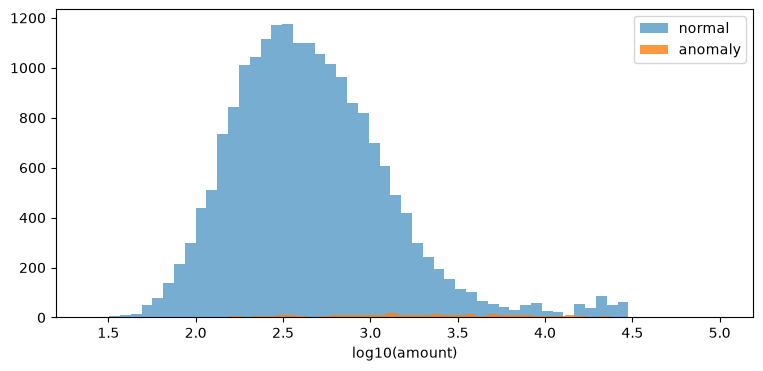

In [8]:
import numpy as np

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(np.log10(normal["amount"]), bins=50, alpha=0.6, label="normal")
ax.hist(np.log10(df[df["is_anomaly"] == 1]["amount"]), bins=50, alpha=0.8, label="anomaly")
ax.set_xlabel("log10(amount)")
ax.legend()
plt.show()